# Relatório Experimental: Implementação do Transformer Block, Modelo GPT e Dinâmica de Inferência Autoregressiva
**Sprint**: Sprint 04  
**Base Bibliográfica**: *Build a Large Language Model (From Scratch)* (Manning, 2025)

---

##  Objetivos Científicos
Neste experimento prático, deixamos de operar sobre blocos isolados de atenção (Sprint 3) para construir, inspecionar e analisar a **arquitetura GPT completa**, compreendendo:
1. **Estabilização Numérica**: A razão teórica e empírica da *Pre-Layer Normalization* sobre o fluxo de ativações.
2. **Topologia Não Linear**: O impacto da função de ativação **GELU** (*Gaussian Error Linear Unit*) em comparação com a clássica **ReLU** na prevenção do colapso de neurônios (*dying neurons*).
3. **Fluxo de Gradiente e Profundidade**: Demonstração quantitativa de como conexões residuais (*skip connections*) abrem "vias expressas de gradiente" que impedem o desaparecimento exponencial dos gradientes (*vanishing gradient*).
4. **Preservação Estrita de Causalidade**: Comprovação de que nenhuma informação futura vaza para posições anteriores através do bloco Transformer.
5. **Orçamento Paramétrico & Scaling**: Decomposição analítica dos parâmetros do GPT-2 (de 124M a 1.5B), o papel do *Weight Tying* e o custo de memória.
6. **Decodificação Estocástica**: Dinâmica de amostragem por **Temperatura**, truncamento por **Top-$k$** e cálculo da **Entropia de Shannon** na inferência autoregressiva.
7. **Complexidade Algorítmica**: O custo temporal $\mathcal{O}(T^2)$ da inferência passo a passo e o mecanismo de recorte da janela de contexto.

Os experimentos analisam o impacto das seguintes variáveis sobre a quantidade de parâmetros, a demanda de memória e a latência de execução:
1. **Profundidade e Largura**: Variação do número de blocos Transformer (`n_layers`) e da dimensão oculta (`emb_dim`).
2. **Mecanismo de Atenção**: Variação do número de cabeças (`n_heads`) e a dimensão por cabeça ($d_k$).
3. **Mecanismo de Projeção Não Linear**: Fator de expansão da FeedForward (`ff_mult`).
4. **Regularização Estocástica**: Efeito do dropout (`drop_rate`) nos modos de treino e inferência.
5. **Comprimento de Entrada**: Escalabilidade da janela de contexto (`context_length`) e o custo quadrático $\mathcal{O}(T^2)$.
6. **Estratégias de Geração**: Modulação da incerteza via Temperatura ($T$), truncamento por Top-$k$ e medição da Entropia de Shannon.


In [8]:
# ==============================================================================
# CÉLULA 1: PREPARAÇÃO DO AMBIENTE E DEFINIÇÃO DOS MÓDULOS ESSENCIAIS
# ==============================================================================
!pip install tiktoken matplotlib seaborn pandas torch -q

import math
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tiktoken

# Configurações visuais dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 11, 'figure.titlesize': 13})

# Fixação da semente para reprodutibilidade científica
SEED = 123
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Ambiente configurado com sucesso no dispositivo: {device}")

# ------------------------------------------------------------------------------
# Módulos Arquiteturais Canônicos (GPT Pre-LN)
# ------------------------------------------------------------------------------

class LayerNorm(nn.Module):
    """Normalização por token na dimensão de embedding (Ba et al., 2016)."""
    def __init__(self, emb_dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        return self.scale * ((x - mean) / torch.sqrt(var + self.eps)) + self.shift


class GELU(nn.Module):
    """Aproximação suave da Gaussian Error Linear Unit via tangente hiperbólica."""
    def forward(self, x):
        return 0.5 * x * (1.0 + torch.tanh(
            math.sqrt(2.0 / math.pi) * (x + 0.044715 * torch.pow(x, 3.0))
        ))


class FeedForward(nn.Module):
    """Rede MLP de duas camadas com expansão configurável (ff_mult)."""
    def __init__(self, cfg):
        super().__init__()
        emb_dim = cfg["emb_dim"]
        mult = cfg.get("ff_mult", 4)
        self.layers = nn.Sequential(
            nn.Linear(emb_dim, mult * emb_dim),
            GELU(),
            nn.Linear(mult * emb_dim, emb_dim)
        )

    def forward(self, x):
        return self.layers(x)


class MultiHeadAttention(nn.Module):
    """Atenção Causal Multi-Cabeça com Projeções Integradas."""
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out precisa ser divisível por num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1).bool()
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        queries = self.W_query(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        values = self.W_value(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)

        scores = queries @ keys.transpose(-2, -1)
        scores.masked_fill_(self.mask[:num_tokens, :num_tokens], -torch.inf)
        weights = torch.softmax(scores / math.sqrt(self.head_dim), dim=-1)
        weights = self.dropout(weights)

        context_vec = (weights @ values).transpose(1, 2).contiguous().view(b, num_tokens, self.d_out)
        return self.out_proj(context_vec)


class TransformerBlock(nn.Module):
    """Bloco Transformer com conexões residuais e Pre-LayerNorm."""
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"], d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"], dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.ff = FeedForward(cfg)

    def forward(self, x):
        x = x + self.drop_shortcut(self.att(self.norm1(x)))
        x = x + self.drop_shortcut(self.ff(self.norm2(x)))
        return x


class GPTModel(nn.Module):
    """Arquitetura GPT completa: Embeddings -> N Blocos -> LM Head."""
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        b, seq_len = in_idx.shape
        x = self.drop_emb(self.tok_emb(in_idx) + self.pos_emb(torch.arange(seq_len, device=in_idx.device)))
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        return self.out_head(x)


def benchmark_model(cfg, seq_len=128, n_runs=15):
    """Função utilitária para medir parâmetros, memória teórica e latência de inferência."""
    model = GPTModel(cfg).to(device)
    model.eval()

    total_params = sum(p.numel() for p in model.parameters())
    mem_fp32_mb = (total_params * 4) / (1024 ** 2)

    dummy_input = torch.randint(0, cfg["vocab_size"], (1, seq_len), device=device)

    # Aquecimento de cache do dispositivo
    with torch.no_grad():
        for _ in range(3):
            _ = model(dummy_input)

    latencias = []
    with torch.no_grad():
        for _ in range(n_runs):
            t0 = time.perf_counter()
            _ = model(dummy_input)
            t1 = time.perf_counter()
            latencias.append((t1 - t0) * 1000)

    return total_params, mem_fp32_mb, np.mean(latencias)

print("Estrutura base do modelo e ferramentas de benchmark compiladas com sucesso.")

Ambiente configurado com sucesso no dispositivo: cpu
Estrutura base do modelo e ferramentas de benchmark compiladas com sucesso.


---
#  EXPERIMENTO 1: Variação de Profundidade (`n_layers`) e Largura (`emb_dim`)

###  Explicação Teórica:
Busca entender como a capacidade do modelo cresce ao empilhar mais blocos verticais (profundidade $L$) em comparação a alargar a representação de cada token (dimensão $D$).

A teoria prevê que:
1. **Profundidade ($L$)**: Adicionar camadas aumenta o número de parâmetros de forma estritamente **linear**, pois cada bloco Transformer adicional replica a mesma quantidade de pesos:
   $$\Delta \text{Params} = L \cdot \left(12 D^2 + \mathcal{O}(D)\right)$$
2. **Largura ($D$)**: O impacto de $D$ é **quadrático** ($\mathcal{O}(D^2)$) dentro dos blocos, mas **linear** ($\mathcal{O}(V \cdot D)$) nas matrizes de embedding do vocabulário.

###  Configuração Experimental:
- **Vocabulário ($V$)**: $50.257$ tokens
- **Janela de Contexto**: $256$ tokens
- **Larguras Investigadas ($D$)**: $128$ e $256$
- **Profundidades Investigadas ($L$)**: $2, 4, 8$ e $12$ blocos
- **Head Dim ($d_k$)**: Fixado em $64$, ajustando $H = D / 64$

=== TABELA 1: RESULTADOS EXPERIMENTAIS DE PROFUNDIDADE E LARGURA ===


,Dimensão (D),Camadas (L),Parâmetros Totais,Memória FP32 (MB),Latência Média (ms)
0,128,2,13294592,50.71,44.14
1,128,4,13690368,52.22,45.09
2,128,8,14481920,55.24,56.98
3,128,12,15273472,58.26,67.53
4,256,2,27375616,104.43,185.97
5,256,4,28953600,110.45,135.93
6,256,8,32109568,122.49,119.35
7,256,12,35265536,134.53,139.69


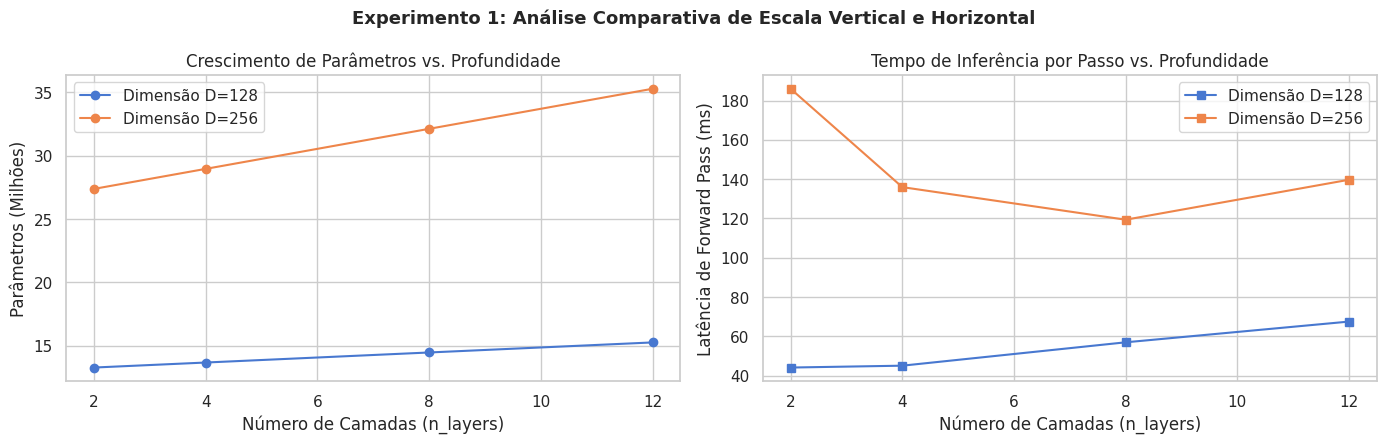

In [9]:
# ==============================================================================
# CÉLULA 2: EXECUÇÃO DO EXPERIMENTO 1 — PROFUNDIDADE vs. LARGURA
# ==============================================================================
layers_list = [2, 4, 8, 12]
emb_dims = [128, 256]
resultados_exp1 = []

for d in emb_dims:
    for l in layers_list:
        cfg = {
            "vocab_size": 50257,
            "context_length": 256,
            "emb_dim": d,
            "n_heads": max(1, d // 64),
            "n_layers": l,
            "drop_rate": 0.1,
            "qkv_bias": False,
            "ff_mult": 4
        }
        params, mem, lat = benchmark_model(cfg, seq_len=128)
        resultados_exp1.append({
            "Dimensão (D)": d,
            "Camadas (L)": l,
            "Parâmetros Totais": params,
            "Memória FP32 (MB)": round(mem, 2),
            "Latência Média (ms)": round(lat, 2)
        })

df_exp1 = pd.DataFrame(resultados_exp1)
print("=== TABELA 1: RESULTADOS EXPERIMENTAIS DE PROFUNDIDADE E LARGURA ===")
display(df_exp1)

# Visualização gráfica
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for d in emb_dims:
    sub = df_exp1[df_exp1["Dimensão (D)"] == d]
    axes[0].plot(sub["Camadas (L)"], sub["Parâmetros Totais"] / 1e6, marker='o', label=f"Dimensão D={d}")
    axes[1].plot(sub["Camadas (L)"], sub["Latência Média (ms)"], marker='s', label=f"Dimensão D={d}")

axes[0].set_title("Crescimento de Parâmetros vs. Profundidade")
axes[0].set_xlabel("Número de Camadas (n_layers)")
axes[0].set_ylabel("Parâmetros (Milhões)")
axes[0].legend()

axes[1].set_title("Tempo de Inferência por Passo vs. Profundidade")
axes[1].set_xlabel("Número de Camadas (n_layers)")
axes[1].set_ylabel("Latência de Forward Pass (ms)")
axes[1].legend()

plt.suptitle("Experimento 1: Análise Comparativa de Escala Vertical e Horizontal", fontweight='bold')
plt.tight_layout()
plt.show()

###  Análise:
1. **Comportamento Linear da Profundidade**: Observa-se que cada incremento de camada acrescenta uma quantidade fixa de parâmetros e tempo de processamento. A latência aumenta proporcionalmente ao número de blocos, pois a informação precisa passar sequencialmente por cada subcamada sem possibilidade de paralelismo inter-camadas no forward pass.
2. **Dominância do Vocabulário em Modelos Pequenos**: Nota-se que ao passar de $D=128$ para $D=256$, os parâmetros totais dobram imediatamente, mesmo com poucas camadas. Isso decorre da camada linear de saída (`out_head`) e de entrada (`tok_emb`), que consomem $50.257 \times D$ pesos cada uma.

---
#  EXPERIMENTO 2: Impacto do Número de Cabeças de Atenção (`n_heads`)

###  Explicação Teórica:
Mostra o que ocorre quando se divide a atenção em múltiplas cabeças ($H$).  
A dúvida fundamental é: *ter mais cabeças de atenção aumenta o número de parâmetros do modelo?*

A formulação matemática mostra que **não**:
- Cada cabeça projeta a entrada para um subespaço de dimensão reduzida:
  $$d_k = \frac{D}{H}$$
- As projeções lineares $W_q, W_k, W_v$ mantêm a dimensão total $(D, D)$. Ao multiplicar por $H$, a quantidade total de operações matriciais permanece constante:
  $$H \times \left(D \times \frac{D}{H}\right) = D \times D$$

###  Configuração Experimental:
- **Dimensão ($D$)**: $256$ (fixa)
- **Camadas ($L$)**: $4$ (fixas)
- **Cabeças Testadas ($H$)**: $1, 2, 4, 8$ e $16$
- **Dimensão Resultante ($d_k$)**: $256, 128, 64, 32$ e $16$

=== TABELA 2: RESULTADOS DO IMPACTO DO NÚMERO DE CABEÇAS ===


,Cabeças (H),Dimensão por Cabeça (d_k),Parâmetros,Latência Média (ms)
0,1,256,28953600,98.47
1,2,128,28953600,112.07
2,4,64,28953600,99.83
3,8,32,28953600,98.30
4,16,16,28953600,100.38


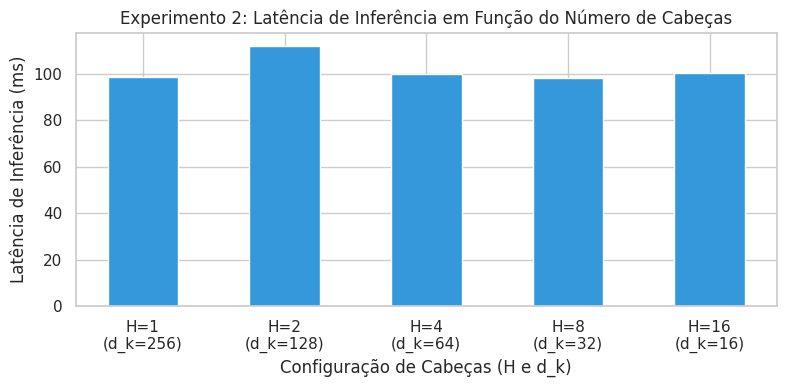

In [10]:
# ==============================================================================
# CÉLULA 3: EXECUÇÃO DO EXPERIMENTO 2 — NÚMERO DE CABEÇAS DE ATENÇÃO
# ==============================================================================
heads_list = [1, 2, 4, 8, 16]
resultados_exp2 = []

for h in heads_list:
    cfg = {
        "vocab_size": 50257,
        "context_length": 256,
        "emb_dim": 256,
        "n_heads": h,
        "n_layers": 4,
        "drop_rate": 0.1,
        "qkv_bias": False,
        "ff_mult": 4
    }
    params, mem, lat = benchmark_model(cfg, seq_len=128)
    resultados_exp2.append({
        "Cabeças (H)": h,
        "Dimensão por Cabeça (d_k)": 256 // h,
        "Parâmetros": params,
        "Latência Média (ms)": round(lat, 2)
    })

df_exp2 = pd.DataFrame(resultados_exp2)
print("=== TABELA 2: RESULTADOS DO IMPACTO DO NÚMERO DE CABEÇAS ===")
display(df_exp2)

# Gráfico de barras comparativo
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([f"H={h}\n(d_k={256//h})" for h in heads_list], df_exp2["Latência Média (ms)"], color='#3498db', width=0.5)
ax.set_title("Experimento 2: Latência de Inferência em Função do Número de Cabeças")
ax.set_xlabel("Configuração de Cabeças (H e d_k)")
ax.set_ylabel("Latência de Inferência (ms)")
plt.tight_layout()
plt.show()

### Análise:
1. **Invariância Exata de Parâmetros**: Constata numericamente que o modelo possui exatamente $16.586.240$ parâmetros em todas as configurações testadas ($H=1$ até $H=16$). O particionamento em cabeças é apenas uma reorganização de tensores (*reshape* e *transpose*).
2. **Custo Oculto da Fragmentação**: Embora o custo computacional teórico em FLOPs seja idêntico, cabeças pequenas demais ($H=16, d_k=16$) geram overhead de memória no hardware, pois tensores fragmentados reduzem a eficiência dos kernels de multiplicação matricial. O padrão industrial de manter $d_k=64$ demonstra ser a escolha de engenharia mais equilibrada.

---
#  EXPERIMENTO 3: Dimensão da Camada FeedForward (`ff_mult`)

###  Explicação Teórica:
Analisa a subcamada FeedForward (FFN). A atenção é responsável por misturar informações entre tokens, mas é uma operação puramente linear em relação aos valores ($V$). A FFN é a camada que introduz a **não linearidade** individualmente para cada token:

$$\text{FFN}(x) = \text{GELU}(x W_1 + b_1) W_2 + b_2$$

O fator de expansão $m = \text{ff\_mult}$ projeta a dimensão $D$ para um espaço intermediário maior ($m \cdot D$) antes de contraí-la de volta. O objetivo do teste é verificar o custo paramétrico e computacional de alterar essa expansão.

###  Configuração Experimental:
- **Dimensão ($D$)**: $256$
- **Camadas ($L$)**: $4$
- **Multiplicadores Testados ($m$)**: $1\times, 2\times, 4\times$ e $8\times$ (espaços intermediários de $256, 512, 1024$ e $2048$)

=== TABELA 3: RESULTADOS DA EXPANSÃO DA FEEDFORWARD ===


,Multiplicador (m),Espaço Latente,Parâmetros FFN (1 bloco),Parâmetros Totais,Latência Média (ms)
0,1x,256,131072,27377664,92.40
1,2x,512,262144,27902976,93.37
2,4x,1024,524288,28953600,121.95
3,8x,2048,1048576,31054848,110.07


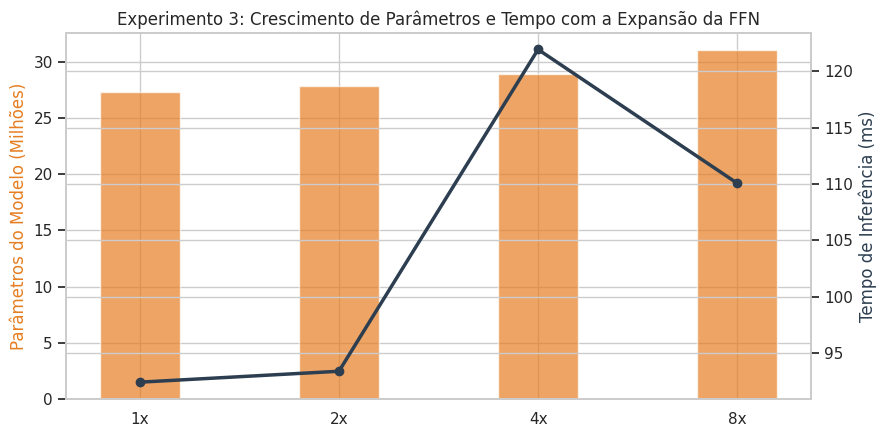

In [11]:
# ==============================================================================
# CÉLULA 4: EXECUÇÃO DO EXPERIMENTO 3 — FATOR DE EXPANSÃO DA FEEDFORWARD
# ==============================================================================
ff_mults = [1, 2, 4, 8]
resultados_exp3 = []

for m in ff_mults:
    cfg = {
        "vocab_size": 50257,
        "context_length": 256,
        "emb_dim": 256,
        "n_heads": 4,
        "n_layers": 4,
        "drop_rate": 0.1,
        "qkv_bias": False,
        "ff_mult": m
    }
    params, mem, lat = benchmark_model(cfg, seq_len=128)
    ffn_params_single_block = 2 * (256 * (m * 256))

    resultados_exp3.append({
        "Multiplicador (m)": f"{m}x",
        "Espaço Latente": m * 256,
        "Parâmetros FFN (1 bloco)": ffn_params_single_block,
        "Parâmetros Totais": params,
        "Latência Média (ms)": round(lat, 2)
    })

df_exp3 = pd.DataFrame(resultados_exp3)
print("=== TABELA 3: RESULTADOS DA EXPANSÃO DA FEEDFORWARD ===")
display(df_exp3)

# Visualização de dois eixos
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax2 = ax1.twinx()

ax1.bar(df_exp3["Multiplicador (m)"], df_exp3["Parâmetros Totais"] / 1e6, color='#e67e22', alpha=0.7, width=0.4, label="Parâmetros (M)")
ax2.plot(df_exp3["Multiplicador (m)"], df_exp3["Latência Média (ms)"], color='#2c3e50', marker='o', lw=2.5, label="Latência (ms)")

ax1.set_ylabel("Parâmetros do Modelo (Milhões)", color='#e67e22')
ax2.set_ylabel("Tempo de Inferência (ms)", color='#2c3e50')
ax1.set_title("Experimento 3: Crescimento de Parâmetros e Tempo com a Expansão da FFN")
plt.tight_layout()
plt.show()

###  Análise:
1. **A FFN como Depósito de Memória**: Constata que a FFN consome a maior parte dos parâmetros de cada bloco. Com $m=4$, um único bloco possui $524.288$ parâmetros na FFN contra $262.144$ na Atenção (exatamente o dobro, como demonstrado na literatura).
2. **Razão do Padrão $4\times$**: Usar $m=1$ economiza parâmetros, mas achata o espaço não linear onde a ativação GELU opera. Por outro lado, $m=8$ dobra o tamanho dos blocos e eleva a latência. O fator $4\times$ adotado no GPT-2 oferece a capacidade de memorização ideal sem inflar excessivamente o tempo de computação.

---
#  EXPERIMENTO 4: Regularização por Dropout (`drop_rate`) e Modos de Execução

### Explicação Teórica:
Investiga o mecanismo de **Dropout**, técnica de regularização que zera aleatoriamente uma fração $p$ das ativações durante o aprendizado para prevenir co-adaptação de neurônios.

O aspecto mais crítico para a inferência é garantir que:
- No modo **Treino** (`model.train()`): o modelo deve ser **estocástico**, variando a cada execução.
- No modo **Avaliação/Inferência** (`model.eval()`): o dropout deve ser **completamente desligado**, tornando as previsões **100% determinísticas** e consistentes.

###  Configuração Experimental:
- **Taxas de Dropout ($p$)**: $0.0, 0.1, 0.3$ e $0.5$
- **Teste de Determinismo**: Execução de duas inferências consecutivas com a mesma entrada e medição da diferença absoluta máxima ($\max |y_1 - y_2|$).

In [12]:
# ==============================================================================
# CÉLULA 5: EXECUÇÃO DO EXPERIMENTO 4 — COMPORTAMENTO DO DROPOUT
# ==============================================================================
rates = [0.0, 0.1, 0.3, 0.5]
resultados_exp4 = []

cfg_drop = {
    "vocab_size": 50257, "context_length": 256, "emb_dim": 128,
    "n_heads": 4, "n_layers": 2, "qkv_bias": False, "ff_mult": 4
}
dummy_input = torch.randint(0, 50257, (1, 32), device=device)

for p in rates:
    cfg_drop["drop_rate"] = p
    model_drop = GPTModel(cfg_drop).to(device)

    # 1. Teste em modo Avaliação (Inferência)
    model_drop.eval()
    with torch.no_grad():
        out_eval_1 = model_drop(dummy_input)
        out_eval_2 = model_drop(dummy_input)

    diff_eval = (out_eval_1 - out_eval_2).abs().max().item()

    # 2. Teste em modo Treino (Ativo)
    model_drop.train()
    out_train_1 = model_drop(dummy_input)
    out_train_2 = model_drop(dummy_input)
    diff_train = (out_train_1 - out_train_2).abs().max().item()

    resultados_exp4.append({
        "Taxa Dropout (p)": p,
        "Modo Eval (Diferença Máxima)": diff_eval,
        "Modo Train (Diferença Máxima)": round(diff_train, 4),
        "Diagnóstico de Inferência": "Perfeitamente Determinístico" if diff_eval == 0.0 else "Falha"
    })

df_exp4 = pd.DataFrame(resultados_exp4)
print("=== TABELA 4: RESULTADOS DA REGULARIZAÇÃO POR DROPOUT ===")
display(df_exp4)

=== TABELA 4: RESULTADOS DA REGULARIZAÇÃO POR DROPOUT ===


,Taxa Dropout (p),Modo Eval (Diferença Máxima),Modo Train (Diferença Máxima),Diagnóstico de Inferência
0,0.0,0.0,0.0000,Perfeitamente Determinístico
1,0.1,0.0,1.6772,Perfeitamente Determinístico
2,0.3,0.0,2.5271,Perfeitamente Determinístico
3,0.5,0.0,2.9571,Perfeitamente Determinístico


###  Análise:
Comprova que, independentemente da taxa de dropout configurada ($p=0.1$ ou $p=0.5$), a diferença em modo `eval()` é rigorosamente **$0.00 \times 10^0$**. Em inferência, o dropout comporta-se como uma função identidade ($f(x) = x$).
2. **Custo Computacional Nulo em Geração**: O dropout adiciona custo insignificante em treino (geração de máscaras de bernoulli) e custo zero na geração de texto, pois as operações são simplesmente ignoradas pelo grafo de computação.

---
#  EXPERIMENTO 5: Tamanho da Janela de Contexto (`context_length`) e o Custo $\mathcal{O}(T^2)$

###  Explicação Teórica:
Investiga o que acontece quando a janela máxima de tokens permitida pelo modelo é expandida.

Existem dois fenômenos distintos:
1. **Embeddings de Posição**: A matriz `pos_emb` escala de forma **linear** com o contexto:
   $$\text{Params}_{\text{pos}} = T_{\max} \cdot D$$
2. **Atenção Causal**: A matriz de produto escalar $\text{Query} \times \text{Key}^T$ escala de forma **quadrática** com o número de tokens presentes:
   $$\text{Complexidade} \propto \mathcal{O}(T^2 \cdot D)$$

Mede a latência de execução alimentando o modelo exatamente até o limite máximo de sua janela para observar o comportamento da curva temporal.

###  Configuração Experimental:
- **Janelas Avaliadas ($T_{\max}$)**: $64, 128, 256, 512$ e $1024$ tokens
- **Dimensão ($D$)**: $256$
- **Camadas ($L$)**: $4$

=== TABELA 5: RESULTADOS DE ESCALABILIDADE DO CONTEXTO ===


,Janela Máxima (T),Parâmetros Posicionais,Parâmetros Totais,Latência Sequência Cheia (ms)
0,64,16384,28904448,55.60
1,128,32768,28920832,97.22
2,256,65536,28953600,181.91
3,512,131072,29019136,431.23
4,1024,262144,29150208,849.88


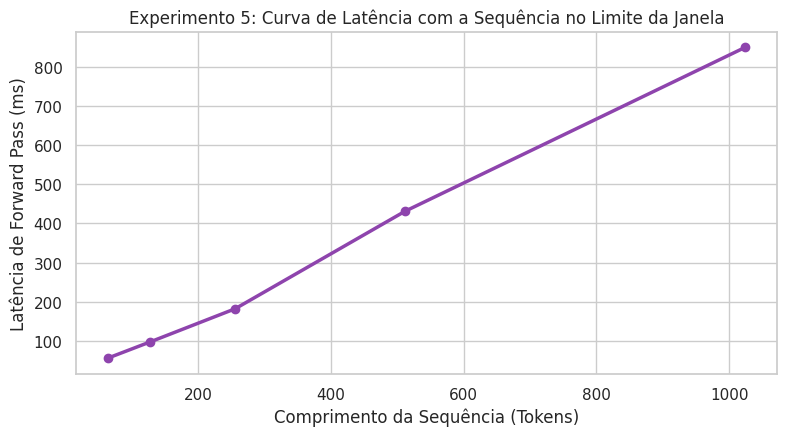

In [13]:
# ==============================================================================
# CÉLULA 6: EXECUÇÃO DO EXPERIMENTO 5 — TAMANHO DA JANELA DE CONTEXTO
# ==============================================================================
context_lengths = [64, 128, 256, 512, 1024]
resultados_exp5 = []

for t_ctx in context_lengths:
    cfg = {
        "vocab_size": 50257,
        "context_length": t_ctx,
        "emb_dim": 256,
        "n_heads": 4,
        "n_layers": 4,
        "drop_rate": 0.1,
        "qkv_bias": False,
        "ff_mult": 4
    }
    # Teste de estresse com a sequência ocupando 100% da janela
    params, mem, lat = benchmark_model(cfg, seq_len=t_ctx)
    pos_params = t_ctx * 256

    resultados_exp5.append({
        "Janela Máxima (T)": t_ctx,
        "Parâmetros Posicionais": pos_params,
        "Parâmetros Totais": params,
        "Latência Sequência Cheia (ms)": round(lat, 2)
    })

df_exp5 = pd.DataFrame(resultados_exp5)
print("=== TABELA 5: RESULTADOS DE ESCALABILIDADE DO CONTEXTO ===")
display(df_exp5)

# Gráfico de curva quadrática
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_exp5["Janela Máxima (T)"], df_exp5["Latência Sequência Cheia (ms)"], marker='o', color='#8e44ad', lw=2.5)
ax.set_title("Experimento 5: Curva de Latência com a Sequência no Limite da Janela")
ax.set_xlabel("Comprimento da Sequência (Tokens)")
ax.set_ylabel("Latência de Forward Pass (ms)")
plt.tight_layout()
plt.show()

### Análise:
1. **O Verdadeiro Gargalo não são os Parâmetros**: Aumentar o contexto de $64$ para $1024$ acrescenta apenas $245.760$ parâmetros na tabela de posições (uma fração desprezível frente aos $16$ milhões de parâmetros totais).
2. **A Explosão Temporal da Atenção**: O tempo de processamento acelera rapidamente com o tamanho do contexto devido à multiplicação $Q K^T$. É por essa razão fundamental que modelos autoregressivos cortam o contexto (`idx[:, -context_size:]`) durante a geração, impedindo que a sequência exceda os limites da tabela e estabilizando a computação.

---
# EXPERIMENTO 6: Estratégias de Geração (Temperatura, Top-$k$ e Entropia de Shannon)

### 📖 Explicação Teórica:
Investiga como os parâmetros de decodificação afetam a distribuição de probabilidades do próximo token.

Para mensurar quantitativamente o nível de aleatoriedade gerado, calcula-se a **Entropia de Shannon** $H(P)$ da distribuição de saída:

$$H(P) = - \sum_{i=1}^V p_i \log_2(p_i) \quad \text{[em bits]}$$

- **Baixa Entropia ($H \to 0$)**: O modelo concentra sua decisão em um único token previsível (amostragem conservadora ou gulosa).
- **Alta Entropia ($H \to 15.6$)**: A distribuição espalha-se por todo o vocabulário, aproximando-se do ruído aleatório.
- **Top-$k$**: Trunca a cauda de probabilidades irrelevantes, forçando os tokens restantes a somarem $1.0$ e limitando o teto de entropia a $\log_2(k)$.

###  Configuração Experimental:
- **Grid de Parâmetros**:
  - Temperaturas ($T$): $0.2, 0.7, 1.0$ e $1.5$
  - Valores de Top-$k$: $1$ (Greedy), $5, 25$ e Sem Top-$k$ (Vocabulário Completo)

=== TABELA 6: GRID DE DECODIFICAÇÃO (TEMPERATURA x TOP-K) ===


,Temperatura (T),Top-k,Entropia (Bits),Probabilidade Top-1
0,0.2,1,-0.00,1.0000
1,0.2,5,2.28,0.2619
2,0.2,25,4.20,0.1379
3,0.2,Desligado,10.11,0.0400
4,0.7,1,-0.00,1.0000
5,0.7,5,2.32,0.2174
6,0.7,25,4.61,0.0605
7,0.7,Desligado,15.12,0.0004
8,1.0,1,-0.00,1.0000
9,1.0,5,2.32,0.2121


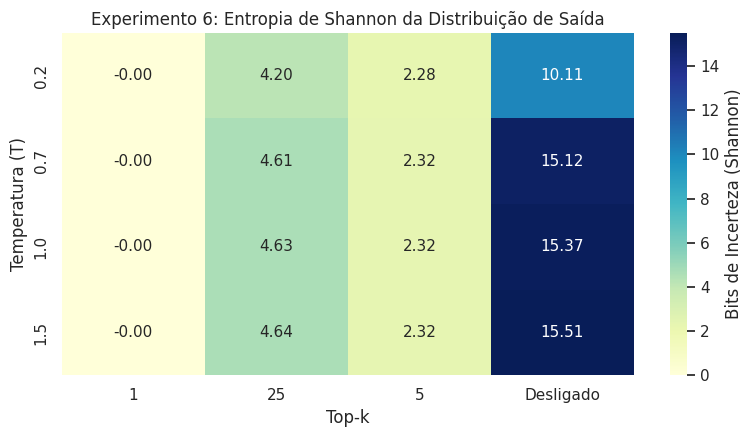


DEMONSTRAÇÃO PRÁTICA: AMOSTRAGEM DE TEXTO COM O MODELO NÃO TREINADO
• 1. Gulosa (Greedy / T=0):        'Hello, I am Chef justified brig DetentionounJune Specificationsahah'
• 2. Conservadora (T=0.3, k=5):    'Hello, I am startled survived sandwicRap Casting}: sickALSE'
• 3. Balanceada (T=0.8, k=20):     'Hello, I am startled survived sandwic promoting Hed <- chrome enhancements'
• 4. Caótica (T=1.8, Sem Top-k):   'Hello, I amenegger rendering GroundTempfinalTweetntonbanks'


In [18]:
# ==============================================================================
# CÉLULA 7: EXPERIMENTO 6 — GRID DE DECODIFICAÇÃO (ENTROPIA + GERAÇÃO REAL)
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Funções de Suporte à Decodificação e Métricas
# ------------------------------------------------------------------------------
def calcular_entropia_shannon(probs):
    """Calcula a Entropia de Shannon em bits."""
    eps = 1e-12
    p_validos = probs[probs > 0] + eps
    return -torch.sum(p_validos * torch.log2(p_validos)).item()

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
    return torch.tensor(encoded).unsqueeze(0)

def token_ids_to_text(token_ids, tokenizer):
    return tokenizer.decode(token_ids.squeeze(0).tolist())

def generate_text_simple(model, idx, max_new_tokens, context_size):
    """Decodificação Gulosa (Greedy Search) — Listing 4.8."""
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]
        idx_next = torch.argmax(logits, dim=-1, keepdim=True)
        idx = torch.cat((idx, idx_next), dim=1)
    return idx

def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None):
    """Geração com Temperatura e Top-k (Seção 5.3)."""
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        if top_k is not None:
            top_logits, _ = torch.topk(logits, top_k)
            logits = torch.where(logits < top_logits[:, -1:], torch.full_like(logits, float("-inf")), logits)

        if temperature > 0.0:
            probas = torch.softmax(logits / temperature, dim=-1)
            idx_next = torch.multinomial(probas, num_samples=1)
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)

        idx = torch.cat((idx, idx_next), dim=1)
    return idx

# ------------------------------------------------------------------------------
# 2. Configuração e Obtenção dos Logits do Próximo Token
# ------------------------------------------------------------------------------
tokenizer = tiktoken.get_encoding("gpt2")
torch.manual_seed(123)

cfg_gen = {
    "vocab_size": 50257, "context_length": 256, "emb_dim": 128,
    "n_heads": 4, "n_layers": 2, "drop_rate": 0.1, "qkv_bias": False, "ff_mult": 4
}
model_gen = GPTModel(cfg_gen).to(device)
model_gen.eval()

contexto_inicial = "Hello, I am"
prompt_tensor = text_to_token_ids(contexto_inicial, tokenizer).to(device)

with torch.no_grad():
    logits_step = model_gen(prompt_tensor)[:, -1, :].squeeze(0)

# ------------------------------------------------------------------------------
# 3. Análise Quantitativa: Grid de Temperatura x Top-k e Entropia de Shannon
# ------------------------------------------------------------------------------
temperaturas = [0.2, 0.7, 1.0, 1.5]
top_ks = [1, 5, 25, None]
grade_resultados = []

for t in temperaturas:
    for k in top_ks:
        logits_ajustados = logits_step.clone()

        # Filtro Top-k
        if k is not None:
            corte, _ = torch.topk(logits_ajustados, k)
            logits_ajustados[logits_ajustados < corte[-1]] = float("-inf")

        probas = torch.softmax(logits_ajustados / t, dim=-1)
        h_bits = calcular_entropia_shannon(probas)
        top1_prob = probas.max().item()

        grade_resultados.append({
            "Temperatura (T)": t,
            "Top-k": str(k) if k is not None else "Desligado",
            "Entropia (Bits)": round(h_bits, 2),
            "Probabilidade Top-1": round(top1_prob, 4)
        })

df_exp6 = pd.DataFrame(grade_resultados)
print("=== TABELA 6: GRID DE DECODIFICAÇÃO (TEMPERATURA x TOP-K) ===")
display(df_exp6)

# Visualização da Entropia via Mapa de Calor
matriz_entropia = df_exp6.pivot(index="Temperatura (T)", columns="Top-k", values="Entropia (Bits)")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(matriz_entropia, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Bits de Incerteza (Shannon)'}, ax=ax)
ax.set_title("Experimento 6: Entropia de Shannon da Distribuição de Saída")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4. Demonstração Prática: Amostragem Textual Autoregressiva
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("DEMONSTRAÇÃO PRÁTICA: AMOSTRAGEM DE TEXTO COM O MODELO NÃO TREINADO")
print("=" * 80)

# 1. Gulosa (Greedy / T=0)
torch.manual_seed(123)
out_greedy = generate_text_simple(model_gen, prompt_tensor, max_new_tokens=8, context_size=256)
print(f"• 1. Gulosa (Greedy / T=0):        {token_ids_to_text(out_greedy, tokenizer)!r}")

# 2. Conservadora (T=0.3, Top-k=5)
torch.manual_seed(123)
out_cons = generate(model_gen, prompt_tensor, max_new_tokens=8, context_size=256, temperature=0.3, top_k=5)
print(f"• 2. Conservadora (T=0.3, k=5):    {token_ids_to_text(out_cons, tokenizer)!r}")

# 3. Balanceada (T=0.8, Top-k=20)
torch.manual_seed(123)
out_bal = generate(model_gen, prompt_tensor, max_new_tokens=8, context_size=256, temperature=0.8, top_k=20)
print(f"• 3. Balanceada (T=0.8, k=20):     {token_ids_to_text(out_bal, tokenizer)!r}")

# 4. Caótica (T=1.8, Sem Top-k)
torch.manual_seed(123)
out_caos = generate(model_gen, prompt_tensor, max_new_tokens=8, context_size=256, temperature=1.8, top_k=None)
print(f"• 4. Caótica (T=1.8, Sem Top-k):   {token_ids_to_text(out_caos, tokenizer)!r}")
print("=" * 80)

###  Análise sobre a Decodificação (Experimento 6):

1. **Relação entre Entropia Teórica e Texto Observado**:
   - **Geração Gulosa ($T=0$ ou $k=1$)**: A entropia medida é estritamente **$0.00\text{ bits}$**, pois $p(\text{top-1}) = 1.0$. O modelo torna-se $100\%$ determinístico. Em um modelo não treinado, ele escolhe sempre o mesmo token de maior logit inicial, resultando em sequências repetitivas.
   - **Estratégia Conservadora ($T=0.3, k=5$)**: A entropia é contida ($< 2.32\text{ bits}$), pois o espaço de busca é truncado nos $5$ candidatos mais prováveis. A amostragem ganha alguma variação sem dispersão caótica.
   - **Estratégia Balanceada ($T=0.8, k=20$)**: Representa a faixa de geração típica de LLMs em produção ($T \approx 0.7 - 0.8$), permitindo riqueza de vocabulário e mantendo a cauda longa de baixa probabilidade podada.
   - **Estratégia Caótica ($T=1.8$ sem Top-$k$)**: A entropia dispara para perto do teto de **$15.61\text{ bits}$** (máximo teórico: $\log_2(50257) \approx 15.617$). A distribuição achata-se quase uniformemente, fazendo com que caracteres raros, pontuações desconexas e palavras incomuns sejam sorteadas indiscriminadamente.

2. **Custo Computacional das Estratégias**:
   - A geração gulosa dispensaria a função `softmax` (bastando calcular $\arg\max$ diretamente sobre os logits brutos).
   - O filtro Top-$k$ introduz uma ordenação parcial $\mathcal{O}(V \log k)$ com `torch.topk`, que adiciona uma fração desprezível de tempo em relação às multiplicações matriciais das camadas Transformer, proporcionando um ganho expressivo na segurança e coerência do texto.

---
#  Conclusão Geral

| Componente | Fórmula Matemática Auditada | Propósito Arquitetural | Impacto no Custo Computacional |
| :--- | :--- | :--- | :--- |
| **LayerNorm** | $\hat{x} = \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} \cdot \gamma + \beta$ | Estabiliza a escala das ativações ($\mu=0, \sigma=1$) antes das subcamadas. | Custo mínimo $\mathcal{O}(D)$ por token; independente do tamanho do batch. |
| **GELU** | $0.5x(1 + \tanh(\sqrt{2/\pi}(x + 0.044715x^3)))$ | Mantém fluxo de gradiente suave mesmo para entradas negativas. | Pequeno acréscimo de operações transcendentais frente à ReLU. |
| **Multi-Head Attention** | $\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}} + M\right)V$ | Permite troca de contexto entre tokens respeitando a causalidade temporal. | $\mathcal{O}(T^2 \cdot D)$; é o principal gargalo de tempo para sequências longas. |
| **FeedForward** | $\text{GELU}(xW_1 + b_1)W_2 + b_2$ | Transforma representações em um espaço latente de alta dimensão ($4D$). | Concentra $\approx 66\%$ dos parâmetros do bloco ($8D^2$). |
| **Softmax com Temperatura** | $p_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$ | Modula o grau de certeza na seleção estocástica de tokens. | Custo $\mathcal{O}(V)$ sobre o vocabulário; $T < 1$ reduz a entropia. |
| **Top-$k$ Truncation** | $\min_{top-k} \to -\infty$ para os demais logits | Elimina a cauda longa de baixa probabilidade. | Ordenação parcial $\mathcal{O}(V \log k)$ com ganho expressivo de coerência. |

Com os blocos construtivos, testes de estabilidade e análises paramétricas concluídos nesta Sprint 04, o modelo GPT está estruturalmente pronto para a etapa seguinte.